# Détection intelligente des intrusions réseau par Machine Learning
## Projet APSI-NE — Sujet A

**Étudiant :** Seydou Dangande Abdoul Aziz  
**Formation :** Informatique — Génie logiciel, EMIG | Projet final APSI-NE  
**Dataset :** UNSW-NB15

## Objectif
Construire et évaluer un pipeline de détection d'intrusions réseau, depuis l'exploration des données jusqu'à l'analyse des erreurs, la visualisation, la simulation d'une dérive et les recommandations de gouvernance.

## Plan en 10 étapes
1. Présentation du problème et du dataset
2. Chargement et exploration des données
3. Nettoyage et préparation des variables
4. Modèle supervisé : Random Forest
5. Modèle de détection d'anomalies : Isolation Forest
6. Évaluation et analyse des erreurs
7. Tableau de bord de synthèse SOC
8. Simulation de dérive et mesure de son impact
9. Explicabilité, gouvernance et surveillance
10. Conclusion et vérification des livrables

# Étape 1 — Problème et choix du dataset

Le problème étudié est la distinction entre le trafic réseau normal et le trafic associé à une attaque. Le dataset UNSW-NB15 est utilisé car il contient des observations de trafic normal et plusieurs catégories d'attaques réseau.

Les fichiers d'entraînement et de test fournis sont conservés séparément. La cible `label` est binaire : `0` correspond au trafic normal et `1` au trafic d'attaque. La colonne `attack_cat` est exclue des variables d'entrée afin de ne pas fournir indirectement au modèle la catégorie de l'attaque.

**Référence scientifique du dataset :**

Moustafa, N. et Slay, J. (2015). *UNSW-NB15: a comprehensive data set for network intrusion detection systems (UNSW-NB15 network data set).* Military Communications and Information Systems Conference (MilCIS), 2015. DOI : [10.1109/MILCOM.2015.735891](https://doi.org/10.1109/MILCOM.2015.735891).

Le dataset a été élaboré par le Cyber Range Lab de l'UNSW Canberra. Les fichiers locaux `UNSW_NB15_training-set.csv` et `UNSW_NB15_testing-set.csv` constituent les jeux d'entraînement et de test utilisés dans cette étude.

# Étape 2 — Chargement et exploration des données

Cette étape vérifie la structure, les types, les valeurs manquantes, les doublons et la répartition des classes. Les résultats sont calculés à partir des fichiers réellement chargés : ne pas remplacer ces sorties par des chiffres recopiés d'une exécution antérieure.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Détection de la racine du projet à partir du dossier courant ou de ses parents.
candidats = [Path.cwd(), *Path.cwd().parents]
racine = next(
    (p for p in candidats if (p / "data/raw/UNSW_NB15_training-set.csv").is_file()),
    None
)
if racine is None:
    raise FileNotFoundError(
        "Dataset introuvable. Placez le notebook dans le projet qui contient "
        "'data/raw/UNSW_NB15_training-set.csv' et 'data/raw/UNSW_NB15_testing-set.csv'."
    )

DATA_DIR = racine / "data" / "raw"
DOSSIER_RESULTATS = racine / "results"
DOSSIER_FIGURES = DOSSIER_RESULTATS / "figures"
DOSSIER_RESULTATS.mkdir(parents=True, exist_ok=True)
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATA_DIR / "UNSW_NB15_training-set.csv")
test = pd.read_csv(DATA_DIR / "UNSW_NB15_testing-set.csv")

print("Racine du projet :", racine)
print("Dimensions entraînement :", train.shape)
print("Dimensions test :", test.shape)
display(train.head())

Racine du projet : /home/seydou-dangande-abdoul-aziz/Bureau/Mr_Robot/Projet_personnel/apsi-ne-projet
Dimensions entraînement : (175341, 45)
Dimensions test : (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


Types de colonnes :


,Nombre
Type,
int64,30
float64,11
str,4


,Valeurs manquantes,Pourcentage manquant,Type
id,0,0.0,int64
dur,0,0.0,float64
proto,0,0.0,str
service,0,0.0,str
state,0,0.0,str
spkts,0,0.0,int64
dpkts,0,0.0,int64
sbytes,0,0.0,int64
dbytes,0,0.0,int64
rate,0,0.0,float64


Lignes dupliquées — entraînement : 0
Lignes dupliquées — test : 0
Valeurs infinies — entraînement : 0
Valeurs infinies — test : 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,175341.0,NaN,NaN,NaN,87671.0,50616.731112,1.0,43836.0,87671.0,131506.0,175341.0
dur,175341.0,NaN,NaN,NaN,1.359389,6.480249,0.0,0.000008,0.001582,0.668069,59.999989
proto,175341,133,tcp,79946,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service,175341,13,-,94168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,175341,9,INT,82275,NaN,NaN,NaN,NaN,NaN,NaN,NaN
spkts,175341.0,NaN,NaN,NaN,20.298664,136.887597,1.0,2.0,2.0,12.0,9616.0
dpkts,175341.0,NaN,NaN,NaN,18.969591,110.258271,0.0,0.0,2.0,10.0,10974.0
sbytes,175341.0,NaN,NaN,NaN,8844.843836,174765.644309,28.0,114.0,430.0,1418.0,12965233.0
dbytes,175341.0,NaN,NaN,NaN,14928.918564,143654.217718,0.0,0.0,164.0,1102.0,14655550.0
rate,175341.0,NaN,NaN,NaN,95406.187105,165400.978457,0.0,32.78614,3225.80652,125000.0003,1000000.003


,Entraînement (%),Test (%)
label,,
Normal (0),31.94,44.94
Attaque (1),68.06,55.06


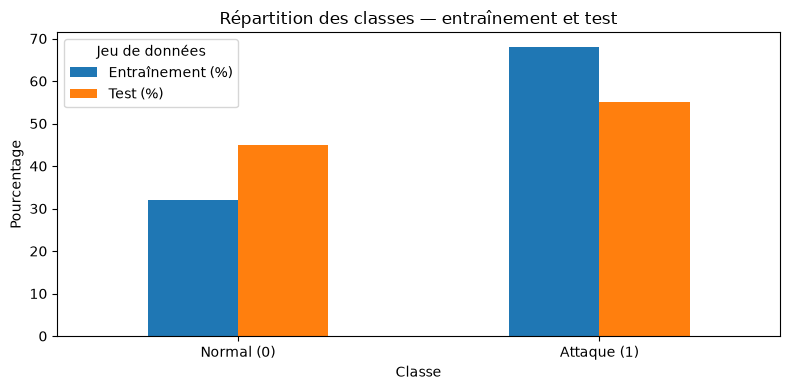

In [2]:
print("Types de colonnes :")
display(train.dtypes.value_counts().rename_axis("Type").to_frame("Nombre"))

qualite = pd.DataFrame({
    "Valeurs manquantes": train.isna().sum(),
    "Pourcentage manquant": (train.isna().mean() * 100).round(3),
    "Type": train.dtypes.astype(str),
})
display(qualite.sort_values("Valeurs manquantes", ascending=False).head(15))

print("Lignes dupliquées — entraînement :", train.duplicated().sum())
print("Lignes dupliquées — test :", test.duplicated().sum())
print("Valeurs infinies — entraînement :", int(np.isinf(train.select_dtypes(include=np.number)).sum().sum()))
print("Valeurs infinies — test :", int(np.isinf(test.select_dtypes(include=np.number)).sum().sum()))
display(train.describe(include="all").T.head(20))

# Comparaison des proportions des classes dans les deux jeux.
repartition_train = train["label"].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100
repartition_test = test["label"].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100
comparaison_classes = pd.DataFrame({
    "Entraînement (%)": repartition_train,
    "Test (%)": repartition_test,
}).rename(index={0: "Normal (0)", 1: "Attaque (1)"})
display(comparaison_classes.round(2))

ax = comparaison_classes.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_title("Répartition des classes — entraînement et test")
ax.set_xlabel("Classe")
ax.set_ylabel("Pourcentage")
ax.legend(title="Jeu de données")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "repartition_classes_train_test.png", dpi=180, bbox_inches="tight")
plt.show()


**Interprétation :** le tableau et le graphique comparent directement la proportion de trafic normal et de trafic d'attaque dans les jeux d'entraînement et de test. Des proportions proches indiquent une répartition globale comparable, mais ne garantissent pas que toutes les caractéristiques réseau suivent la même distribution. Un déséquilibre de classes peut favoriser la classe majoritaire ; c'est pourquoi le rappel, la précision, le F1 et les matrices de confusion sont également étudiés. Les contrôles de valeurs manquantes, doublons et valeurs infinies permettent de repérer des problèmes de qualité avant l'apprentissage.

# Étape 3 — Nettoyage et préparation des variables

Les colonnes `id`, `label` et `attack_cat` ne sont pas utilisées comme variables explicatives. Les variables catégorielles sont encodées avec One-Hot Encoding. Les variables numériques sont conservées pour Random Forest et standardisées pour Isolation Forest.

Les transformations sont intégrées dans des pipelines : elles sont ajustées sur les données d'entraînement seulement, ce qui réduit le risque de fuite de données.

In [3]:
colonnes_a_exclure = ["id", "label", "attack_cat"]
colonnes_absentes = [c for c in colonnes_a_exclure if c not in train.columns or c not in test.columns]
if colonnes_absentes:
    raise ValueError(f"Colonnes attendues absentes : {colonnes_absentes}")

X_train = train.drop(columns=colonnes_a_exclure)
y_train = train["label"].astype(int)
X_test = test.drop(columns=colonnes_a_exclure)
y_test = test["label"].astype(int)

if set(y_train.unique()) - {0, 1} or set(y_test.unique()) - {0, 1}:
    raise ValueError("La cible label doit contenir uniquement 0 et 1.")

colonnes_categorielles = X_train.select_dtypes(include=["object", "category", "str"]).columns.tolist()
colonnes_numeriques = X_train.select_dtypes(include=np.number).columns.tolist()

print("Nombre de variables explicatives :", X_train.shape[1])
print("Variables numériques :", len(colonnes_numeriques))
print("Variables catégorielles :", colonnes_categorielles)
print("Répartition train :")
display(y_train.value_counts(normalize=True).rename("Proportion").to_frame())
print("Répartition test :")
display(y_test.value_counts(normalize=True).rename("Proportion").to_frame())

Nombre de variables explicatives : 42
Variables numériques : 39
Variables catégorielles : ['proto', 'service', 'state']
Répartition train :


,Proportion
label,
1,0.680622
0,0.319378


Répartition test :


,Proportion
label,
1,0.5506
0,0.4494


# Étape 4 — Modèle supervisé : Random Forest

Random Forest apprend à partir des exemples étiquetés. `class_weight="balanced"` ajuste le poids des classes pendant l'apprentissage. Le modèle est évalué sur le jeu de test officiel, qui n'est pas utilisé pour ajuster le prétraitement ni entraîner le modèle.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

preprocesseur_rf = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), colonnes_categorielles),
        ("num", "passthrough", colonnes_numeriques),
    ],
    remainder="drop"
)

modele_rf = Pipeline([
    ("pretraitement", preprocesseur_rf),
    ("modele", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

print("Entraînement de Random Forest…")
modele_rf.fit(X_train, y_train)
y_pred_rf = modele_rf.predict(X_test)
y_prob_rf = modele_rf.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, y_pred_rf, labels=[0, 1],
    target_names=["Normal", "Attaque"], digits=4, zero_division=0
))
print("ROC-AUC :", round(roc_auc_score(y_test, y_prob_rf), 4))

Entraînement de Random Forest…
              precision    recall  f1-score   support

      Normal     0.9629    0.7922    0.8693     37000
     Attaque     0.8519    0.9751    0.9093     45332

    accuracy                         0.8929     82332
   macro avg     0.9074    0.8837    0.8893     82332
weighted avg     0.9018    0.8929    0.8913     82332

ROC-AUC : 0.9807


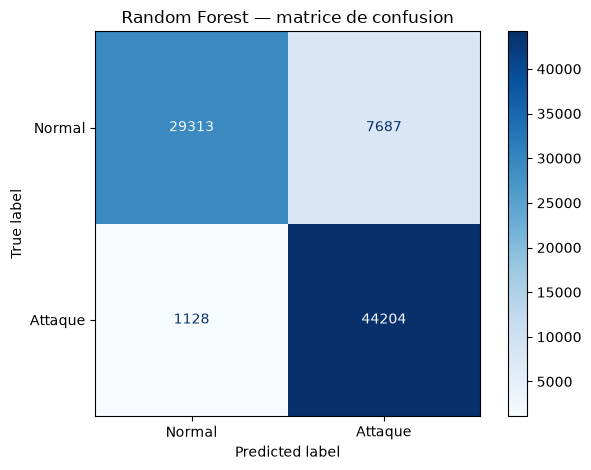

In [5]:
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])
ConfusionMatrixDisplay(cm_rf, display_labels=["Normal", "Attaque"]).plot(
    values_format="d", cmap="Blues"
)
plt.title("Random Forest — matrice de confusion")
plt.tight_layout()
plt.show()

# Étape 5 — Modèle de détection d'anomalies : Isolation Forest

Isolation Forest est ajusté uniquement sur les observations normales du jeu d'entraînement. La prédiction brute `-1` signifie anomalie et `1` signifie observation considérée comme normale. Le seuil automatique (`contamination="auto"`) est conservé pour cette expérience de référence ; ses limites seront discutées.

In [6]:
preprocesseur_if = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), colonnes_categorielles),
        ("num", StandardScaler(), colonnes_numeriques),
    ],
    remainder="drop"
)

X_train_normal = X_train.loc[y_train == 0]
modele_if = Pipeline([
    ("pretraitement", preprocesseur_if),
    ("modele", IsolationForest(
        n_estimators=100,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    ))
])

print("Entraînement d'Isolation Forest sur le trafic normal…")
modele_if.fit(X_train_normal)
pred_brutes_if = modele_if.predict(X_test)
y_pred_if = np.where(pred_brutes_if == -1, 1, 0)
scores_anomalie_if = -modele_if.decision_function(X_test)

print(classification_report(
    y_test, y_pred_if, labels=[0, 1],
    target_names=["Normal", "Attaque"], digits=4, zero_division=0
))
print("ROC-AUC :", round(roc_auc_score(y_test, scores_anomalie_if), 4))

Entraînement d'Isolation Forest sur le trafic normal…
              precision    recall  f1-score   support

      Normal     0.5260    0.9099    0.6667     37000
     Attaque     0.8182    0.3308    0.4712     45332

    accuracy                         0.5911     82332
   macro avg     0.6721    0.6204    0.5689     82332
weighted avg     0.6869    0.5911    0.5590     82332

ROC-AUC : 0.7742


# Étape 6 — Évaluation et analyse des erreurs

Dans un SOC, le rappel des attaques est souvent prioritaire car un faux négatif correspond à une attaque manquée. Toutefois, une précision trop faible génère de nombreux faux positifs et surcharge les analystes. Le choix opérationnel doit donc considérer les deux coûts.

In [7]:
def calculer_metriques(nom, y_true, y_pred, scores):
    return {
        "Modèle": nom,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Précision attaques": precision_score(y_true, y_pred, zero_division=0),
        "Rappel attaques": recall_score(y_true, y_pred, zero_division=0),
        "F1 attaques": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores),
    }

resultats = pd.DataFrame([
    calculer_metriques("Random Forest", y_test, y_pred_rf, y_prob_rf),
    calculer_metriques("Isolation Forest", y_test, y_pred_if, scores_anomalie_if),
])
display(resultats.set_index("Modèle").round(4))

cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])
tn, fp, fn, tp = cm_rf.ravel()
print(f"Random Forest — TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("Taux de faux positifs parmi les normaux :", round(fp / max(tn + fp, 1), 4))
print("Taux de faux négatifs parmi les attaques :", round(fn / max(fn + tp, 1), 4))

# Exemples d'erreurs RF avec leur classe réelle et leur prédiction.
erreurs = test.copy()
erreurs["prediction_rf"] = y_pred_rf
erreurs["score_attaque_rf"] = y_prob_rf
erreurs["type_erreur"] = np.select(
    [
        (y_test.to_numpy() == 0) & (y_pred_rf == 1),
        (y_test.to_numpy() == 1) & (y_pred_rf == 0),
    ],
    ["Faux positif", "Faux négatif"],
    default="Correct"
)
fp_exemples = erreurs[erreurs["type_erreur"] == "Faux positif"].head(5)
fn_exemples = erreurs[erreurs["type_erreur"] == "Faux négatif"].head(5)
print("Exemples de faux positifs :")
display(fp_exemples[[c for c in ["id", "attack_cat", "proto", "service", "state", "label", "prediction_rf", "score_attaque_rf"] if c in erreurs.columns]])
print("Exemples de faux négatifs :")
display(fn_exemples[[c for c in ["id", "attack_cat", "proto", "service", "state", "label", "prediction_rf", "score_attaque_rf"] if c in erreurs.columns]])

# Analyse descriptive des erreurs : catégories et attributs les plus fréquents.
# Ces regroupements décrivent les erreurs observées, sans démontrer leur cause.
for type_erreur in ["Faux positif", "Faux négatif"]:
    sous_ensemble = erreurs[erreurs["type_erreur"] == type_erreur]
    print(f"\n{type_erreur} — nombre total : {len(sous_ensemble)}")
    for variable in ["attack_cat", "proto", "service", "state"]:
        if variable in sous_ensemble.columns and not sous_ensemble.empty:
            print(f"Répartition par {variable} (10 valeurs les plus fréquentes) :")
            display(
                sous_ensemble[variable].fillna("Valeur manquante")
                .value_counts().head(10).rename("Nombre").to_frame()
            )

# Pour les faux négatifs, repérer les scores proches de la frontière 0,5.
if not fn_exemples.empty:
    print("Faux négatifs avec les scores d'attaque les plus proches de 0,5 :")
    display(
        erreurs[erreurs["type_erreur"] == "Faux négatif"]
        .assign(distance_seuil=lambda d: (d["score_attaque_rf"] - 0.5).abs())
        .sort_values("distance_seuil")
        [[c for c in ["id", "attack_cat", "proto", "service", "state", "score_attaque_rf", "distance_seuil"] if c in erreurs.columns]]
        .head(10)
    )

resultats.to_csv(DOSSIER_RESULTATS / "comparaison_modeles.csv", index=False)

,Accuracy,Précision attaques,Rappel attaques,F1 attaques,ROC-AUC
Modèle,,,,,
Random Forest,0.8929,0.8519,0.9751,0.9093,0.9807
Isolation Forest,0.5911,0.8182,0.3308,0.4712,0.7742


Random Forest — TN=29313, FP=7687, FN=1128, TP=44204
Taux de faux positifs parmi les normaux : 0.2078
Taux de faux négatifs parmi les attaques : 0.0249
Exemples de faux positifs :


,id,attack_cat,proto,service,state,label,prediction_rf,score_attaque_rf
0,1,Normal,udp,-,INT,0,1,0.656226
1,2,Normal,udp,-,INT,0,1,0.810000
2,3,Normal,udp,-,INT,0,1,0.584155
3,4,Normal,udp,-,INT,0,1,0.830000
4,5,Normal,udp,-,INT,0,1,0.550000


Exemples de faux négatifs :


,id,attack_cat,proto,service,state,label,prediction_rf,score_attaque_rf
254,255,Exploits,tcp,http,FIN,1,0,0.50
277,278,Fuzzers,tcp,-,FIN,1,0,0.45
281,282,Fuzzers,tcp,-,FIN,1,0,0.43
282,283,Fuzzers,tcp,-,FIN,1,0,0.46
283,284,Fuzzers,tcp,-,FIN,1,0,0.32



Faux positif — nombre total : 7687
Répartition par attack_cat (10 valeurs les plus fréquentes) :


... (13 outputs left out)

Répartition par state (10 valeurs les plus fréquentes) :


,Nombre
state,
FIN,859
INT,269


Faux négatifs avec les scores d'attaque les plus proches de 0,5 :


,id,attack_cat,proto,service,state,score_attaque_rf
254,255,Exploits,tcp,http,FIN,0.5
65422,65423,Fuzzers,udp,-,INT,0.5
288,289,Fuzzers,tcp,-,FIN,0.5
64264,64265,Fuzzers,udp,-,INT,0.5
63552,63553,Fuzzers,udp,-,INT,0.5
62942,62943,Fuzzers,udp,-,INT,0.5
63432,63433,Fuzzers,udp,-,INT,0.5
63044,63045,Fuzzers,tcp,-,FIN,0.5
44782,44783,Fuzzers,tcp,ftp,FIN,0.5
44820,44821,Fuzzers,tcp,ftp,FIN,0.5


**Interprétation :** un faux positif est un trafic normal classé comme attaque ; il augmente la charge d'investigation du SOC. Un faux négatif est une attaque classée comme normale ; il peut laisser une intrusion passer inaperçue. Les tableaux de fréquence permettent d'identifier les protocoles, services, états ou catégories qui apparaissent souvent parmi les erreurs. Il s'agit d'une analyse descriptive : une fréquence élevée ne prouve pas qu'une variable provoque l'erreur. Les faux négatifs dont le score est proche de 0,5 sont particulièrement utiles à examiner, car ils se situent près du seuil de décision par défaut de Random Forest. Une analyse causale demanderait des investigations complémentaires, le contexte des flux et des tests contrôlés. Les résultats restent dépendants de la représentativité du dataset et peuvent varier sur un réseau réel.

# Étape 7 — Tableau de bord de synthèse SOC

Le tableau de bord rassemble les indicateurs principaux, la comparaison des modèles et les matrices de confusion. Il doit permettre à un analyste non-développeur d'identifier rapidement le modèle le plus efficace et les erreurs qui méritent une investigation.

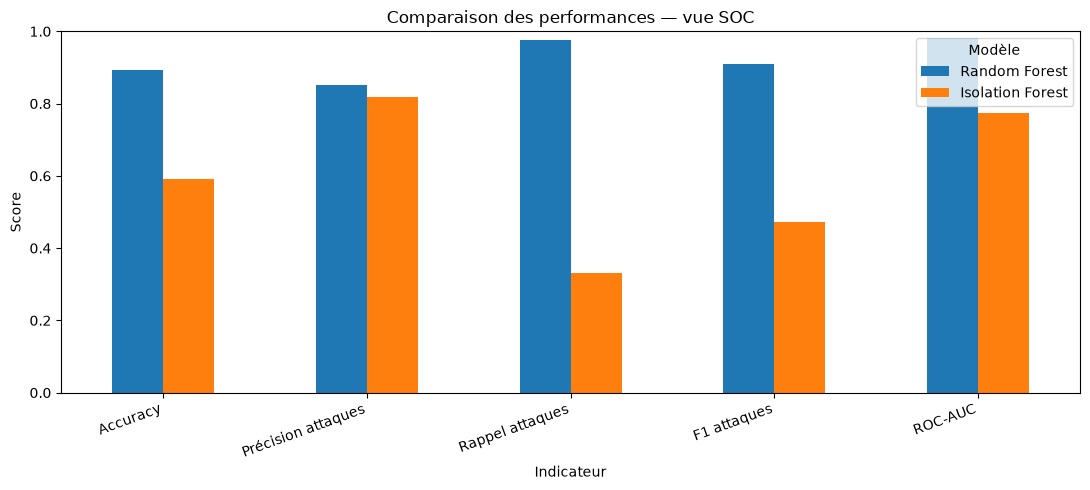

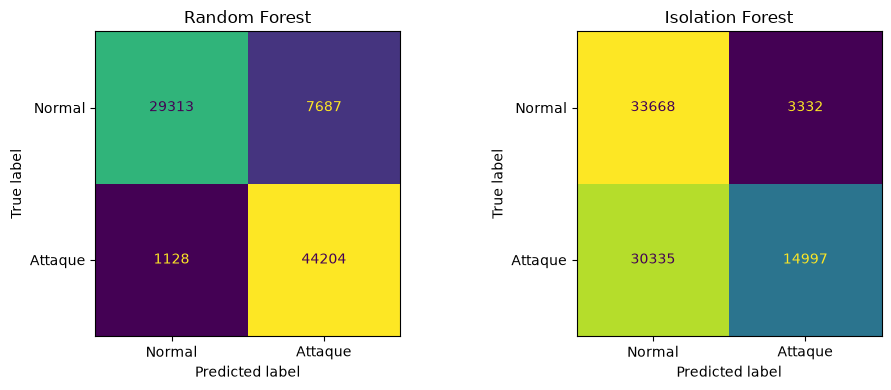

In [8]:
indicateurs = ["Accuracy", "Précision attaques", "Rappel attaques", "F1 attaques", "ROC-AUC"]
ax = resultats.set_index("Modèle")[indicateurs].T.plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1)
)
ax.set_title("Comparaison des performances — vue SOC")
ax.set_ylabel("Score")
ax.set_xlabel("Indicateur")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "comparaison_modeles.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_rf, labels=[0, 1]),
    display_labels=["Normal", "Attaque"]
).plot(ax=axes[0], colorbar=False, values_format="d")
axes[0].set_title("Random Forest")
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_if, labels=[0, 1]),
    display_labels=["Normal", "Attaque"]
).plot(ax=axes[1], colorbar=False, values_format="d")
axes[1].set_title("Isolation Forest")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "matrices_confusion.png", dpi=180, bbox_inches="tight")
plt.show()

# Étape 8 — Simulation de dérive et mesure de son impact

La dérive (data drift) désigne une évolution de la distribution des données reçues. Pour tester la sensibilité du modèle, on crée ici un scénario artificiel en modifiant certaines variables numériques du jeu de test. Cette simulation n'est **pas** une nouvelle attaque réelle et ne permet pas de conclure sur la performance face à une famille d'attaques inconnue.

Le jeu de test original reste intact : la copie modifiée est utilisée uniquement pour cette expérience.

**Limite méthodologique :** le choix des trois premières variables numériques dépend de l'ordre des colonnes du fichier. Il s'agit d'un scénario de stress-test reproductible, et non d'une simulation réaliste de l'évolution d'un réseau. Pour une étude de dérive en production, il faudrait comparer les distributions temporelles de données réelles, documenter les variables concernées et disposer de labels fiables pour mesurer l'évolution des performances. La simulation ne constitue pas un test zero-day.

In [9]:
# Scénario synthétique : décalage de 20 % de certaines variables numériques.
X_test_drift = X_test.copy()
variables_drift = colonnes_numeriques[:min(3, len(colonnes_numeriques))]
for col in variables_drift:
    X_test_drift[col] = X_test_drift[col] * 1.20

y_pred_drift = modele_rf.predict(X_test_drift)
y_prob_drift = modele_rf.predict_proba(X_test_drift)[:, 1]

comparaison_drift = pd.DataFrame([
    {
        "Scénario": "Test original",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Rappel attaques": recall_score(y_test, y_pred_rf, zero_division=0),
        "F1 attaques": f1_score(y_test, y_pred_rf, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob_rf),
    },
    {
        "Scénario": "Test avec dérive synthétique",
        "Accuracy": accuracy_score(y_test, y_pred_drift),
        "Rappel attaques": recall_score(y_test, y_pred_drift, zero_division=0),
        "F1 attaques": f1_score(y_test, y_pred_drift, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob_drift),
    },
])
print("Variables modifiées :", variables_drift)
display(comparaison_drift.round(4))
comparaison_drift.to_csv(DOSSIER_RESULTATS / "impact_drift.csv", index=False)

Variables modifiées : ['dur', 'spkts', 'dpkts']


,Scénario,Accuracy,Rappel attaques,F1 attaques,ROC-AUC
0,Test original,0.8929,0.9751,0.9093,0.9807
1,Test avec dérive synthétique,0.8862,0.9789,0.9045,0.9815


**Interprétation :** la comparaison affichée mesure la variation des performances après le décalage artificiel de 20 % appliqué aux premières variables numériques. Une baisse du rappel ou du F1 indique une sensibilité du modèle à ce scénario. Une variation faible ne garantit pas la robustesse face à de nouvelles attaques. Cette expérience est une simulation contrôlée, pas une preuve de détection zero-day.

# Étape 9 — Explicabilité, gouvernance et surveillance

## Explicabilité
L'importance des variables de Random Forest donne une indication globale des variables utilisées par les arbres. Cette importance ne prouve pas une causalité et n'explique pas à elle seule une alerte individuelle. Une alerte opérationnelle devrait présenter le score, les principales caractéristiques contributives, le contexte réseau et les éléments à vérifier par l'analyste.

## Responsabilité et limites
- Le modèle assiste l'analyste ; il ne doit pas prendre seul une décision disciplinaire ou bloquer une activité critique sans règles de validation adaptées.
- L'analyste SOC reste responsable de l'investigation et de la qualification de l'alerte selon les procédures de l'organisation.
- L'équipe qui déploie le modèle doit documenter les données, les versions, les seuils, les tests et les changements.
- Les données réseau peuvent contenir des informations sensibles : accès restreint, durée de conservation définie et conformité au cadre légal applicable.
- Un faux négatif peut laisser une attaque progresser ; un faux positif peut détourner le temps des analystes et perturber une activité légitime.

## Proposition de monitoring
Surveiller au minimum :
1. La proportion d'alertes et la distribution des scores.
2. Le taux de faux positifs et de faux négatifs dès que des labels fiables sont disponibles.
3. La dérive des variables d'entrée et l'évolution des catégories de trafic.
4. Les temps de traitement et les erreurs du pipeline.

**Seuils initiaux à valider avec le SOC :** déclencher une revue si le rappel mesuré sur un échantillon labellisé baisse de plus de 5 points par rapport à la référence, si la distribution d'une variable clé dérive fortement, ou si le volume d'alertes augmente brutalement. Ces seuils sont des propositions de départ, pas des seuils universels.

**Fréquence proposée :** suivi quotidien des volumes et scores, revue hebdomadaire des dérives, évaluation mensuelle sur données labellisées et réentraînement uniquement après validation d'un changement documenté.

,Variable,Importance
183,num__ct_state_ttl,0.100923
161,num__sttl,0.079687
163,num__sload,0.065337
160,num__rate,0.046190
164,num__dload,0.043103
162,num__dttl,0.040252
158,num__sbytes,0.034707
168,num__dinpkt,0.034257
192,num__ct_srv_dst,0.033800
178,num__smean,0.033410


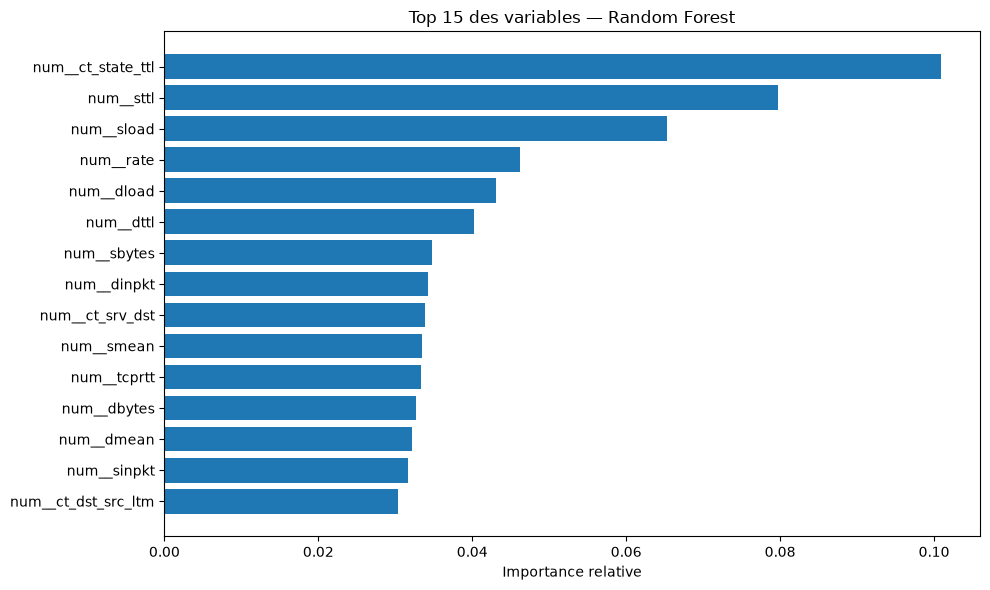

In [10]:
# Importance globale des variables Random Forest
preprocesseur_entraine = modele_rf.named_steps["pretraitement"]
rf_entraine = modele_rf.named_steps["modele"]
noms_variables = preprocesseur_entraine.get_feature_names_out()
importances = pd.DataFrame({
    "Variable": noms_variables,
    "Importance": rf_entraine.feature_importances_
}).sort_values("Importance", ascending=False)

display(importances.head(15))
top15 = importances.head(15).sort_values("Importance")
plt.figure(figsize=(10, 6))
plt.barh(top15["Variable"], top15["Importance"])
plt.xlabel("Importance relative")
plt.title("Top 15 des variables — Random Forest")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "importance_variables.png", dpi=180, bbox_inches="tight")
plt.show()
importances.to_csv(DOSSIER_RESULTATS / "importance_variables.csv", index=False)

# Étape 10 — Conclusion et vérification des livrables

Les résultats calculés dans ce notebook permettent de comparer les deux approches sur UNSW-NB15. Random Forest constitue l'approche supervisée de référence ; Isolation Forest apporte une approche non supervisée entraînée sur le trafic normal. Le choix opérationnel doit privilégier un compromis entre détection des attaques et maîtrise des fausses alertes. Un modèle performant sur UNSW-NB15 n'est pas automatiquement prêt à être déployé dans un SOC réel. Avant tout déploiement, il faut valider les données locales, les seuils, les coûts des erreurs, la robustesse face à la dérive, la capacité de traitement et les procédures de supervision humaine.

## Checklist finale
- [ ] Source du dataset et catégories d'attaques citées dans le rapport.
- [ ] Exploration et visualisations commentées.
- [ ] Prétraitements justifiés et absence de fuite de données vérifiée.
- [ ] Deux modèles comparés, dont Isolation Forest entraîné sur le trafic normal.
- [ ] Métriques, matrices de confusion et coûts FP/FN discutés.
- [ ] Exemples de faux positifs et faux négatifs analysés.
- [ ] Tableau de bord compréhensible par un analyste SOC.
- [ ] Dérive simulée, impact mesuré et limites de la simulation expliquées.
- [ ] Explicabilité, responsabilité, cadre légal et monitoring discutés.
- [ ] Notebook exécuté de haut en bas et rapport de synthèse finalisé.

## Références bibliographiques

1. Moustafa, N. et Slay, J. (2015). *UNSW-NB15: a comprehensive data set for network intrusion detection systems (UNSW-NB15 network data set).* Military Communications and Information Systems Conference (MilCIS), 2015. DOI : [https://doi.org/10.1109/MILCOM.2015.735891](https://doi.org/10.1109/MILCOM.2015.735891).
2. Cyber Range Lab, UNSW Canberra. *The UNSW-NB15 Dataset.* Portail de présentation et de téléchargement : [https://research.unsw.edu.au/projects/unsw-nb15-dataset](https://research.unsw.edu.au/projects/unsw-nb15-dataset).

## Note de reproductibilité

Les métriques, tableaux et graphiques doivent être générés par une exécution complète du notebook avec les deux fichiers CSV du dataset. Les résultats enregistrés dans le notebook doivent correspondre à cette dernière exécution. Le jeu de test est réservé à l'évaluation finale ; il ne doit pas servir à ajuster les transformations ou à entraîner les modèles.


In [11]:
fichiers_attendus = [
    DOSSIER_RESULTATS / "comparaison_modeles.csv",
    DOSSIER_RESULTATS / "impact_drift.csv",
    DOSSIER_RESULTATS / "importance_variables.csv",
    DOSSIER_FIGURES / "repartition_classes_train_test.png",
    DOSSIER_FIGURES / "comparaison_modeles.png",
    DOSSIER_FIGURES / "matrices_confusion.png",
    DOSSIER_FIGURES / "importance_variables.png",
]
verification = pd.DataFrame({
    "Fichier": [str(p.relative_to(racine)) for p in fichiers_attendus],
    "Statut": ["OK" if p.is_file() else "MANQUANT" for p in fichiers_attendus],
})
display(verification)
if not verification["Statut"].eq("OK").all():
    print("Attention : certains livrables intermédiaires sont absents.")
else:
    print("Tous les livrables intermédiaires attendus sont présents.")

,Fichier,Statut
0,results/comparaison_modeles.csv,OK
1,results/impact_drift.csv,OK
2,results/importance_variables.csv,OK
3,results/figures/repartition_classes_train_test...,OK
4,results/figures/comparaison_modeles.png,OK
5,results/figures/matrices_confusion.png,OK
6,results/figures/importance_variables.png,OK


Tous les livrables intermédiaires attendus sont présents.
